# Lesson 7: Neural Network (MLP)

**Goals of this notebook:**
1. Move from classical machine learning to **deep learning**: build a **neural network**, a **multilayer perceptron (MLP)**, on the same data and the same test set as every lesson.
2. Learn the core deep learning ideas: neurons, layers, activation functions, loss, backpropagation, optimizer, epochs, batches, dropout, validation set and early stopping.
3. **See overfitting happen** in a neural network, then fix it (the same story as the unlimited Decision Tree in Lesson 6).
4. Compare **honestly** with every previous model and choose the **final model**.

**Why this step:** after XGBoost, the obvious question is "Did you try deep learning?" This notebook answers it with evidence, including *why* deep learning does or doesn't help on this kind of data.

# Setup

**Imports.**
- **Keras** is a library for building neural networks from simple building blocks called **layers**. Keras describes the network; the **backend** is the engine that does the actual maths. Here the backend is **TensorFlow**.
  (The commented-out `KERAS_BACKEND` line would switch the engine to PyTorch. It is only needed if TensorFlow can't be installed; the rest of the code would stay the same.)
- `layers` contains the building blocks we use: `Dense` (a layer of neurons) and `Dropout` (explained in Part C).
- `joblib` saves the scaler at the end. The scikit-learn tools are the same as in earlier lessons.
- `keras.utils.set_random_seed(42)` fixes all the randomness (the random starting weights, dropout, and the shuffling of customers), so the results are repeatable.
  On this computer, two runs give exactly the same numbers. On a different computer or library version, a neural network's results can differ slightly (by about 0.01). That is normal.

In [1]:
import os
# os.environ["KERAS_BACKEND"] = "torch"   # uncomment ONLY if TensorFlow could not be installed

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

keras.utils.set_random_seed(42)
print("Keras", keras.__version__, "| backend:", keras.config.backend())

Keras 3.15.1 | backend: tensorflow


**Load the data and split it into three parts: train, validation and test.**

```
All 7,043 customers
    Test (1,409)              the final exam: used ONCE, at the very end (the same test set as every lesson)
    Training (5,634)
        Train (4,507)         the network learns from these customers
        Validation (1,127)    a mock exam after every epoch, used to decide when to stop training
```

- The **first split** is exactly the same as in every lesson (`random_state=42`, `stratify=y`), so the test set contains the same 1,409 customers and the comparison with the earlier models is fair.
- The **second split** takes 20% of the training customers as a **validation set**. `stratify=y_train` keeps about 26.5% churners in both parts.

**Why do we need a validation set now?** The earlier models were trained in one go. A neural network trains in many rounds (**epochs**), and after every round we need to check: *is it still improving on customers it hasn't seen?* That check tells us when to stop.
We can't use the test set for this. Checking it after every epoch would be **"peeking at the exam"**, which is data leakage, and the final test score would look better than it really is.
(In Lesson 6B, cross-validation inside the training set played this role for the other models.)

Expected: Train `(4507, 23)`, Validation `(1127, 23)`, Test `(1409, 23)`.

In [2]:
df = pd.read_csv("../data/telco_clean.csv")

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

print("Train:", X_tr.shape, " Validation:", X_val.shape, " Test:", X_test.shape)

Train: (4507, 23)  Validation: (1127, 23)  Test: (1409, 23)


**Scale the numeric columns, and convert everything to arrays.**
- Neural networks **need scaling**, just like Logistic Regression, because they also learn with **gradient descent**. A column with big numbers, like TotalCharges (up to about 8,700), would dominate the weighted sums and make learning slow and unstable.
- The scaler is fit **only on the train part** (4,507 customers) and then just *applied* to the validation and test sets, to avoid leakage. It's the same rule as in Lesson 4, now with one more set.
- `.values.astype("float32")` turns each DataFrame into a plain **NumPy array** of 32-bit decimal numbers. This is the standard input format for neural networks: float32 has enough precision and uses half the memory of the default float64.
  (The arrays have no column names, so the columns must always stay in the same order.)
- The labels (`y`) are converted the same way.

In [3]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_tr_s = X_tr.copy()
X_val_s = X_val.copy()
X_test_s = X_test.copy()
X_tr_s[num_cols] = scaler.fit_transform(X_tr[num_cols])
X_val_s[num_cols] = scaler.transform(X_val[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

X_tr_s = X_tr_s.values.astype("float32")
X_val_s = X_val_s.values.astype("float32")
X_test_s = X_test_s.values.astype("float32")
y_tr_np = y_tr.values.astype("float32")
y_val_np = y_val.values.astype("float32")

print(X_tr_s.shape, X_tr_s.dtype)

(4507, 23) float32


**Class weights for the imbalance.**
Keras has no `class_weight="balanced"` shortcut, so we calculate the weights ourselves, with **exactly the formula scikit-learn uses** for "balanced":

weight of a class = number of customers / (2 x number of customers in that class)

- Expected: about `{0: 0.68, 1: 1.88}`.
- So a mistake on a churner counts 1.88 / 0.68 = **about 2.8 times more** than a mistake on a customer who stays. It's the same idea as `class_weight="balanced"` (Lessons 5 and 6) and `scale_pos_weight` (XGBoost).
- `float(...)` simply turns each result into a normal Python number.

In [4]:
n = len(y_tr)
n_stay = (y_tr == 0).sum()
n_churn = (y_tr == 1).sum()

class_weight = {0: float(n / (2 * n_stay)), 1: float(n / (2 * n_churn))}
print({k: round(v, 2) for k, v in class_weight.items()})

{0: 0.68, 1: 1.88}


# Part A: What is a neural network?

## A neuron
A **neuron** is a mini Logistic Regression. It:
1. multiplies each input by a **weight**,
2. adds them all up, plus one extra number called the **bias** (a starting value, like the intercept in Logistic Regression),
3. and passes the result through an **activation function**.

As a formula, for one neuron with 23 inputs:

`output = activation(w1 * x1 + w2 * x2 + ... + w23 * x23 + b)`

Just like in Logistic Regression, **nobody sets the weights by hand**: the network learns them during training.

## Layers
Neurons are arranged in **layers**. Every neuron in a layer receives **all** the outputs of the layer before it; this is called a **Dense** (or fully connected) layer.
Our network, from the input at the top to the output at the bottom:

```
Input layer      23 inputs (tenure, contract, fiber, and so on)
Hidden layer 1   32 neurons, ReLU activation
Hidden layer 2   16 neurons, ReLU activation
Output layer     1 neuron, sigmoid activation: the churn probability
```

They are called **hidden** layers because we never look at their values directly; we only see the inputs and the final output.

**Key insight:** a network with **no hidden layers** and a sigmoid output **is exactly Logistic Regression** (23 weights and 1 bias, then a sigmoid).
The hidden layers are what let a neural network learn **combinations and non-linear patterns** automatically, for example "short tenure AND fiber optic AND no tech support".
Trees learn such combinations too, but in a different way (with Yes/No questions instead of weighted sums).

## Activation functions
- **ReLU** (Rectified Linear Unit) = `max(0, x)`: if the value is negative, output 0; otherwise pass it through unchanged. It is simple and fast, and it's the standard choice for hidden layers.
- **Why we need it:** without a non-linear activation, every layer would only "multiply and add". But a "multiply and add" of a "multiply and add" is still just one "multiply and add". So stacking layers would collapse into **one linear model**, no better than Logistic Regression. ReLU's bend at 0 is what lets the network build curved, non-linear patterns.
- **Sigmoid** in the output layer squeezes the final score into a **probability between 0 and 1**, exactly like in Logistic Regression (Lesson 5).

## Why is it called "deep" learning?
"Deep" learning simply means networks with **several hidden layers**. Image and language models can have dozens or hundreds of layers and millions (or billions) of weights.
Ours is **small on purpose**: we only have about 4,500 training customers, and a big network would just memorize them (Part B shows this).

## How a neural network learns
It's the same loop as Logistic Regression in Lesson 5, but through several layers:
1. **Forward pass:** the network predicts churn probabilities for a batch of customers (the data flows forward, from the inputs to the output).
2. **Loss:** it measures how wrong those predictions are with **binary cross-entropy**, which is the same thing as the **log loss** from Lesson 5. Confident wrong predictions are punished the most.
3. **Backpropagation:** the error is passed **backward**, from the output layer through each hidden layer, to work out how much **each weight** contributed to the mistake. It's like tracing back through a chain of people who passed on a message, to find out where it went wrong.
4. **Optimizer (Adam):** a smarter version of gradient descent. It nudges every weight a little in the direction that reduces the loss, and it automatically adjusts the step size for each weight.

These four steps repeat for every batch, again and again.

## Epochs and batches
- An **epoch** is one full pass over all 4,507 training customers.
- The **batch size** is how many customers the network looks at before each weight update. With **batch size 32**, the weights are updated after every 32 customers, so there are 4,507 / 32 = **about 141 updates per epoch** (the last batch is a little smaller).
- Updating after every batch, instead of once per epoch, lets the network learn much faster.

# Part B: See overfitting happen

**A network that is too big, with no protection.**
This network has two big hidden layers (128 and 64 neurons), **no dropout** and **no early stopping**, and it trains for a fixed 100 epochs.

How many parameters (weights and biases) does it have?
- Hidden layer 1: 23 x 128 weights + 128 biases = 3,072
- Hidden layer 2: 128 x 64 weights + 64 biases = 8,256
- Output layer: 64 x 1 weight + 1 bias = 65
- **Total: 11,393 parameters** for only 4,507 training customers. That's plenty of capacity to memorize individual customers.

The code, line by line:
- `keras.utils.set_random_seed(42)` again, so this model always starts from the same random weights.
- `keras.Sequential([...])` builds the network as a simple **list of layers**, in order.
- `keras.Input(shape=(X_tr_s.shape[1],))` says that each customer is a row of 23 numbers.
- `layers.Dense(128, activation="relu")` is a fully connected layer of 128 neurons with ReLU.
- `compile(...)` chooses how it learns: the Adam optimizer and the binary cross-entropy loss (explained in more detail in Part C).
- `fit(...)` trains it. `validation_data=` makes Keras compute the **validation loss after every epoch**, `verbose=0` hides the per-epoch printout, and the returned `history` stores the training and validation loss of every epoch.
- `np.argmin(...)` finds the epoch with the **lowest validation loss**. We add 1 because Python counts from 0, but we count epochs from 1.

(No class weights here: this demo is only about overfitting, so we keep it as simple as possible.)

In [5]:
keras.utils.set_random_seed(42)

overfit_model = keras.Sequential([
    keras.Input(shape=(X_tr_s.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
overfit_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                      loss="binary_crossentropy")

overfit_history = overfit_model.fit(X_tr_s, y_tr_np,
                                    validation_data=(X_val_s, y_val_np),
                                    epochs=100, batch_size=32, verbose=0)

best = int(np.argmin(overfit_history.history["val_loss"])) + 1
print("Lowest validation loss at epoch:", best, "of 100")

Lowest validation loss at epoch: 3 of 100


**Plot the loss curves.** The blue line is the loss on the customers the network learns from (training); the orange line is the loss on the validation customers it never learns from.
We number the epochs from 1, so the dashed line sits exactly at the epoch printed above.

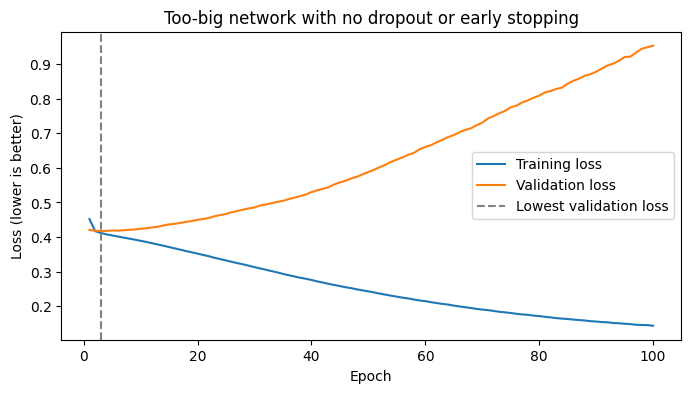

In [6]:
epochs = range(1, len(overfit_history.history["loss"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, overfit_history.history["loss"], label="Training loss")
plt.plot(epochs, overfit_history.history["val_loss"], label="Validation loss")
plt.axvline(best, color="gray", linestyle="--", label="Lowest validation loss")
plt.title("Too-big network with no dropout or early stopping")
plt.xlabel("Epoch")
plt.ylabel("Loss (lower is better)")
plt.legend()
plt.show()

**Put numbers on the gap:** the training and validation loss at the best epoch, and at the last epoch (100).

In [7]:
train_loss = overfit_history.history["loss"]
val_loss = overfit_history.history["val_loss"]

print(f"At epoch {best}:   training loss = {train_loss[best - 1]:.3f}   validation loss = {val_loss[best - 1]:.3f}")
print(f"At epoch 100:  training loss = {train_loss[-1]:.3f}   validation loss = {val_loss[-1]:.3f}")

At epoch 3:   training loss = 0.412   validation loss = 0.418
At epoch 100:  training loss = 0.144   validation loss = 0.953


**What the curves show:**
- The **training loss keeps going down** for all 100 epochs: from 0.412 at epoch 3 to **0.144** at epoch 100. The network gets better and better at the customers it trains on.
- The **validation loss is lowest at epoch 3** (0.418), stays almost flat until about epoch 5, and then keeps rising (from epoch 10 on, it goes up in every single epoch): 0.424 at epoch 10, 0.486 at epoch 30, 0.588 at epoch 50 and **0.953** at epoch 100, more than double its best value.
- From epoch 3 on, the network is **memorizing** the training customers (including their random noise) instead of learning general patterns, so every extra epoch makes it worse on new customers.
- This is the same **overfitting** we saw with the unlimited Decision Tree in Lesson 6 (99.8% train accuracy vs. 72.6% test accuracy). The growing gap between the two curves is the warning sign.
- It happened very quickly: the real patterns in this data are simple, so this big network learned them in only 3 epochs (about 420 weight updates). After that, the only thing left to learn was noise.

We do **not** add this model to the results table. Part C fixes the problem in three ways: a **smaller** network, **dropout**, and **early stopping**.

# Part C: A properly regularized network

**Build the real model: small, with dropout.**
- **Why 32, then 16 neurons?** For 23 features and about 4,500 customers, a small network is enough, and a bigger one overfits (as Part B showed). The "funnel" shape (32, then 16, then 1) gradually squeezes the information down to one churn probability.
- **Dropout(0.3):** during training, at every step, **30% of the neurons are randomly switched off**. The network can't rely on any single neuron, so it has to spread what it learns over many neurons, which generalizes better.
  Think of a team where any member might be absent on a given day: everyone has to understand the job. Dropout is **only active during training**; when predicting, all neurons are used.
- `model.summary()` prints every layer and its number of parameters (weights and biases).

**Counting the parameters** (expected total: **1,313**):
- Hidden layer 1: 23 x 32 weights + 32 biases = 768
- Hidden layer 2: 32 x 16 weights + 16 biases = 528
- Output layer: 16 x 1 weight + 1 bias = 17
- Dropout layers have **no** parameters (they only switch neurons off).
- Total: 768 + 528 + 17 = **1,313**. For comparison, Logistic Regression has only **24** (23 weights and 1 bias), and the too-big network in Part B had 11,393.

In [8]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(X_tr_s.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313 (5.13 KB)

 Trainable params: 1,313 (5.13 KB)

 Non-trainable params: 0 (0.00 B)

**Compile: choose how the network learns.**
- **Optimizer:** Adam, the smarter gradient descent from Part A.
- **Learning rate 0.001:** the size of each step. 0.001 is Adam's standard default: big enough to learn quickly, small enough not to overshoot.
- **Loss:** `binary_crossentropy` (the same as log loss), the error the network tries to make as small as possible.
- **Metric:** `AUC`, a score Keras reports after every epoch so we can watch it. It does not affect learning. We name it `"auc"`, so its validation version is called `"val_auc"`.

Keras computes AUC with an approximation (it checks 200 thresholds), so we use scikit-learn's exact `roc_auc_score` for the official test number.

In [9]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc")])

**Train with early stopping.**
**Early stopping** watches the validation AUC after every epoch:
- `monitor="val_auc", mode="max"`: a higher validation AUC is better.
- `patience=15`: if the validation AUC hasn't improved for **15 epochs in a row**, stop training.
- `restore_best_weights=True`: after stopping, go back to the weights from the **best epoch**, not the last one.

In `fit(...)`:
- `epochs=200` is only an **upper limit**; early stopping ends training much sooner.
- `batch_size=32`: update the weights after every 32 customers.
- `class_weight=class_weight`: mistakes on churners count about 2.8 times more.
- `callbacks=[early_stop]`: a **callback** is a helper that Keras runs at the end of every epoch; here, the early stopping check.
- `verbose=0` hides the per-epoch log (the curves in the next cell show it better).

At the end we print how many epochs actually ran, the best epoch, and the best validation AUC. When training stops early, epochs trained = best epoch + 15 (the patience).

In [10]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                           patience=15, restore_best_weights=True)

history = model.fit(X_tr_s, y_tr_np,
                    validation_data=(X_val_s, y_val_np),
                    epochs=200,
                    batch_size=32,
                    class_weight=class_weight,
                    callbacks=[early_stop],
                    verbose=0)

epochs_run = len(history.history["loss"])
best_epoch = int(np.argmax(history.history["val_auc"])) + 1
print("Epochs trained:", epochs_run, "| Best epoch:", best_epoch,
      "| Best validation AUC:", round(max(history.history["val_auc"]), 3))

Epochs trained: 22 | Best epoch: 7 | Best validation AUC: 0.846


**Training curves:** the loss (left) and the ROC-AUC (right) for every epoch, numbered from 1. The dashed line marks the best epoch, whose weights the model now uses.

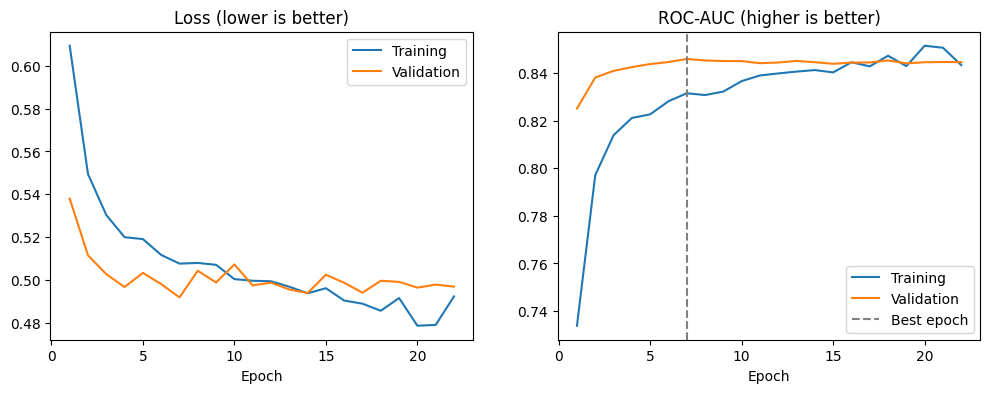

In [11]:
epochs = range(1, epochs_run + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history["loss"], label="Training")
axes[0].plot(epochs, history.history["val_loss"], label="Validation")
axes[0].set_title("Loss (lower is better)")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs, history.history["auc"], label="Training")
axes[1].plot(epochs, history.history["val_auc"], label="Validation")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label="Best epoch")
axes[1].set_title("ROC-AUC (higher is better)")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.show()

**What the curves show (compare with Part B):**
- The two curves **stay close together** the whole time. At the last epoch, the training loss is 0.492 and the validation loss 0.497; in Part B the gap grew to 0.144 vs. 0.953. The small size and dropout stopped the memorizing.
- The **validation AUC rose quickly to about 0.845 by epoch 5 and then stayed flat**. The best value, **0.846**, came at **epoch 7**. It didn't improve for the next 15 epochs, so early stopping ended training at **epoch 22** and restored the weights from epoch 7.
- In the first epochs, the **training loss is higher than the validation loss**. That looks strange, but it's normal here: **dropout** is only active during training (it makes training harder on purpose), and the **class weights** make churner mistakes count more in the training loss only. So the two losses aren't measured in exactly the same way.
- Near the end, the training AUC (about 0.85) slowly **overtakes** the validation AUC: the first sign that the network would start to overfit if it kept training. Early stopping stopped it in time.
- The validation set is small (1,127 customers), so its AUC moves up and down a little from epoch to epoch (here between 0.844 and 0.846). What matters is the overall trend: when the validation curve flattens or turns, it's time to stop.

# Part D: Final exam on the test set

**Evaluate on the test set, for the first and only time.**
- `model.predict(X_test_s)` returns the output of the sigmoid neuron, which **already is** the churn probability of each customer. (Dropout is switched off automatically when predicting.)
- The output has the shape `(1409, 1)`: one column with one probability per customer. `.ravel()` flattens it into a simple list of 1,409 numbers, shape `(1409,)`, which is what the scikit-learn metrics expect.
- `(y_prob >= 0.5).astype(int)`: a probability of 0.5 or higher means "churn" (1), otherwise "stay" (0).
- Then we compute the same 5 metrics and the confusion matrix as for every other model.

Accuracy : 0.745
Precision: 0.513
Recall   : 0.810
F1       : 0.628
ROC-AUC  : 0.842


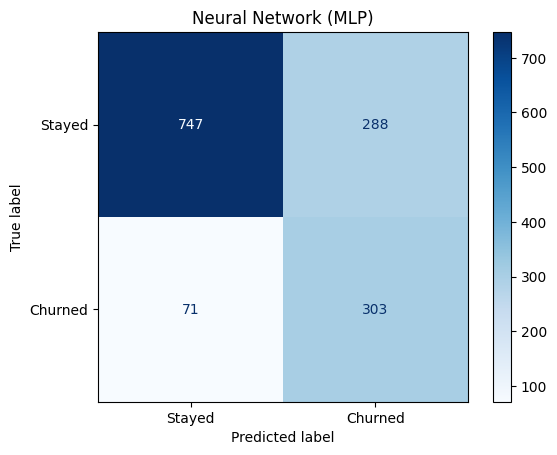

In [12]:
y_prob = model.predict(X_test_s, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

nn_scores = {
    "Model": "Neural Network (MLP)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}
for key, value in nn_scores.items():
    if key != "Model":
        print(f"{key:9}: {value:.3f}")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Neural Network (MLP)")
plt.show()

**Add the MLP to the results table, with no duplicates on a re-run.**
As in Lesson 6B: first remove any existing "Neural Network (MLP)" row, then add the new one and save. Expected: **8 rows**.
The table is **displayed** sorted by ROC-AUC (best first), but the file keeps the original order (from simple to advanced).

In [13]:
results = pd.read_csv("../data/model_results.csv")
results = results[results["Model"] != "Neural Network (MLP)"]
results = pd.concat([results, pd.DataFrame([nn_scores])], ignore_index=True).round(3)
results.to_csv("../data/model_results.csv", index=False)
results.sort_values("ROC-AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
6,XGBoost (tuned),0.750,0.519,0.810,0.633,0.846
4,Random Forest,0.762,0.536,0.759,0.628,0.845
1,Logistic Regression,0.806,0.658,0.556,0.603,0.842
2,Logistic Regression (balanced),0.740,0.507,0.786,0.616,0.842
7,Neural Network (MLP),0.745,0.513,0.810,0.628,0.842
5,XGBoost,0.752,0.522,0.783,0.627,0.840
3,Decision Tree,0.730,0.495,0.807,0.614,0.830
0,Lazy (predict all stay),0.735,0.000,0.000,0.000,0.500


**Compare every model on the same test set.** A horizontal bar chart of Recall, F1 and ROC-AUC for every model except the lazy one, sorted so the best ROC-AUC is at the top.

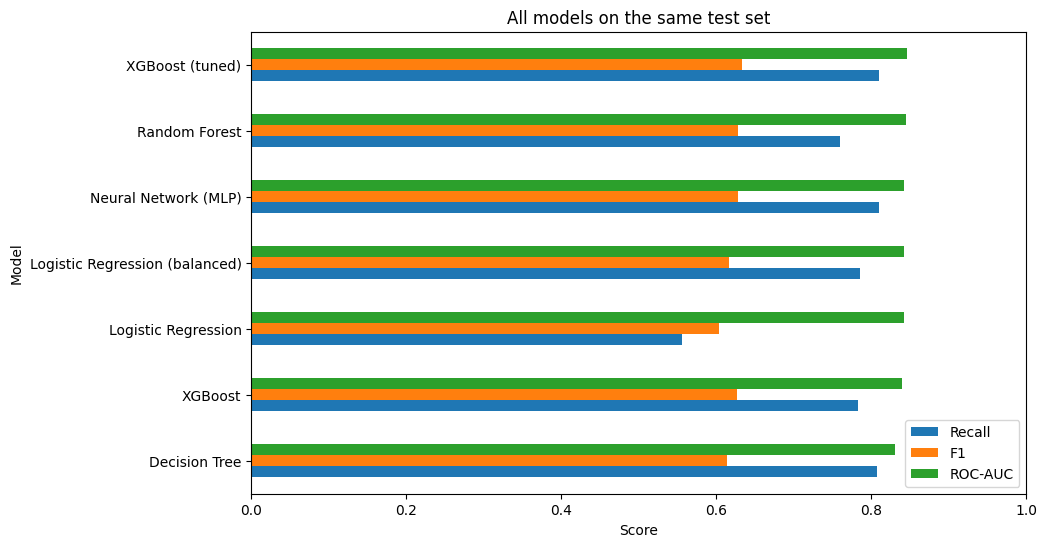

In [14]:
compare = results[results["Model"] != "Lazy (predict all stay)"].sort_values("ROC-AUC")

compare.set_index("Model")[["Recall", "F1", "ROC-AUC"]].plot(kind="barh", figsize=(10, 6))
plt.title("All models on the same test set")
plt.xlabel("Score")
plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.show()

## Honest result
The MLP reached a test **ROC-AUC of 0.842** and a **recall of 0.810**:
- the **same ROC-AUC as Logistic Regression** (0.842, both versions),
- slightly **below tuned XGBoost (0.846)** and Random Forest (0.845),
- and it catches **as many churners as tuned XGBoost** (303 of 374), with a few more false alarms (see Part E).

All these differences are smaller than the noise we measured with cross-validation in Lesson 6B (a standard deviation of about 0.011). So the neural network is **in the same group as the best models, but not better**.

**Why doesn't deep learning win here?**
- **The data is small** for deep learning: about 7,000 customers in total, and the MLP learned from only **4,507** of them, because 1,127 were held back for validation (the other models trained on all 5,634).
- **The features are already meaningful, hand-made columns** (tenure, contract, monthly charges, and so on). Deep learning's big strength is learning useful features from **raw** data (images, text, audio, long sequences), and there is none of that here.
- **The patterns are simple.** The validation AUC reached about 0.845 within 5 epochs and then stayed flat: the same ceiling that every other model reached. There was nothing extra for the network to discover.
- **Research agrees:** on typical tabular datasets, gradient-boosted trees usually match or beat neural networks (Grinsztajn, Oyallon and Varoquaux, "Why do tree-based models still outperform deep learning on typical tabular data?", NeurIPS 2022).

Deep learning pays off with **lots of data** or **raw, sequential data**, such as each customer's daily activity over many months. That is Lesson 8.

**Save the network together with its scaler.**
- `model.save("../models/mlp.keras")` saves the whole network (layers, learned weights, settings) in Keras's own `.keras` file format.
- A neural network must always be saved **together with its scaler**: new customers have to be scaled **exactly the same way** (with the same means and standard deviations from the 4,507 training customers) before predicting. Otherwise the network receives numbers on a different scale and its predictions are wrong.
- The scaler only scales the 3 numeric columns, and the 23 columns must be in the same order as in training (saved in `models/feature_columns.joblib` in Lesson 6B).
- **Reload check:** we load the saved file back and compute the test ROC-AUC again. It must match the score above, which proves the file works.

In [15]:
os.makedirs("../models", exist_ok=True)

model.save("../models/mlp.keras")
joblib.dump(scaler, "../models/mlp_scaler.joblib")

reloaded = keras.models.load_model("../models/mlp.keras")
check = roc_auc_score(y_test, reloaded.predict(X_test_s, verbose=0).ravel())
print("Reloaded MLP ROC-AUC:", round(check, 3))

Reloaded MLP ROC-AUC: 0.842


# Part E: Choose the final model

**Compare the two final candidates side by side.**
We load the tuned XGBoost model saved in Lesson 6B and count, for both models, how many churners each one catches and how many false alarms it raises.
- XGBoost gets the **unscaled** test data (`X_test`), because trees don't need scaling. The MLP's predictions (`y_pred`) come from Part D.
- `confusion_matrix(...).ravel()` turns the 2 by 2 matrix into four numbers, in the order TN, FP, FN, TP.

In [16]:
xgb_final = joblib.load("../models/xgb_tuned.joblib")
xgb_pred = xgb_final.predict(X_test)

for name, pred in [("Tuned XGBoost", xgb_pred), ("Neural Network (MLP)", y_pred)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name:22}: churners caught = {tp} of {tp + fn}   false alarms = {fp}")

Tuned XGBoost         : churners caught = 303 of 374   false alarms = 281
Neural Network (MLP)  : churners caught = 303 of 374   false alarms = 288


**The decision rule:** switch to the MLP only if it is **clearly better** than tuned XGBoost, meaning a ROC-AUC higher by more than about 0.01 **and** a similar or better recall.

| Test set (1,409 customers) | Tuned XGBoost | Neural Network (MLP) |
|---|---|---|
| ROC-AUC | **0.846** | 0.842 |
| Recall | 0.810 (303 of 374 churners) | 0.810 (303 of 374 churners) |
| Precision | **0.519** | 0.513 |
| False alarms | **281** | 288 |
| F1 | **0.633** | 0.628 |

The MLP is **not** clearly better: its ROC-AUC is 0.004 **lower**, it catches the same number of churners, and it raises 7 more false alarms.

**Final model: tuned XGBoost (`models/xgb_tuned.joblib`)**, because:
1. It performs **as well or slightly better** on the test set.
2. Its performance is **confirmed by 5-fold cross-validation** (ROC-AUC 0.849 in Lesson 6B), while the MLP's score comes from a single split and a single random seed.
3. It **needs no scaling**: to score a new customer, we only need the model file and the column order. The MLP also needs its scaler, and the two must always be kept together.
4. It can be **explained for every customer with SHAP** (Lesson 6B), which the retention team needs in order to choose the right offer.

The MLP stays saved in `models/` as an honest, documented comparison.

## Findings (Lesson 7)
1. A too-big network (11,393 parameters) without dropout or early stopping **overfit**: its validation loss was lowest at **epoch 3** (0.418) and then kept rising, to 0.953 by epoch 100, while its training loss kept falling, to 0.144.
2. The regularized MLP (32 and 16 neurons, ReLU, dropout 0.3, sigmoid output, Adam, binary cross-entropy, class weights, early stopping on validation AUC) has **1,313 parameters**. It trained for **22 epochs**; the best epoch was **7**, with a validation AUC of 0.846.
3. Test results: **ROC-AUC 0.842**, **recall 0.810**, precision 0.513, F1 0.628, accuracy 0.745.
4. The MLP was **similar to, but not better than**, tuned XGBoost (ROC-AUC 0.846), and equal to balanced Logistic Regression (0.842). It caught the same number of churners as tuned XGBoost (303 of 374), with 7 more false alarms. This matches research: on small tabular datasets, tree models usually match or beat neural networks.
5. **Final model: tuned XGBoost.** It is as good or slightly better, its score is confirmed by cross-validation, it needs no scaler, and it is explainable with SHAP.

## Why move on (later lessons)
- **Lesson 8:** the Telco data is one **snapshot** per customer. Deep learning's real advantage is learning from **sequences**, like each customer's daily activity over months. Lesson 8 uses LSTM/GRU models on behavioral logs (the KKBox dataset).
- **Lesson 9:** turn predictions into action: rank customers by churn risk and customer value, map segments to retention offers, and serve the model through an API and a dashboard.